In [1]:
def classify_rainfall(values, wet_threshold=0.05, prominence=0.2, min_separation=2):
    values = np.asarray(values, dtype=float)
    wet = np.flatnonzero(values > wet_threshold)

    if len(wet) == 0:
        return {'n_peaks': 0, 'modality': 'dry', 'peaks': [], 'trimmed_values': values[:0]}

    values = values[wet[0]:wet[-1] + 1]

    peaks, props = find_peaks(values, height=20, distance=min_separation)

    # Include endpoints as potential peaks if they are sufficiently prominent
#     if len(values) > 1 and values[0] > values[1] and values[0] - np.min(values) >= prominence:
#         peaks = np.append(peaks, 0)
#     if len(values) > 1 and values[-1] > values[-2] and values[-1] - np.min(values) >= prominence:
#         peaks = np.append(peaks, len(values) - 1)

    peaks = np.unique(peaks)
    n_peaks = len(peaks)

    modality = 'unimodal' if n_peaks == 1 else 'bimodal' if n_peaks == 2 else 'multimodal' if n_peaks > 2 else 'no clear peak'

    return {'n_peaks': n_peaks, 'modality': modality, 'peaks': peaks, 'trimmed_values': values}

def classify_modality(values, height=10, min_distance=3, wet_threshold=0.05):
    
    if len(values) == 0 or np.max(values) <= 0:
        print("HELP!!")
        return {'n_peaks': 0, 'modality': 'no clear peak', 'peaks': np.array([], dtype=int), 'trimmed_values': values}

    # Short events: explicitly identify the maximum
    if len(values) <= 2:
        peaks = np.array([np.argmax(values)])
    else:
        peaks, _ = find_peaks(values, height=10, distance=min_distance)
        
        # Allow for the peak coming first
        if values[0] >= height and (len(values) == 1 or values[0] > values[1]):
            peaks = np.append(peaks, 0)

        if len(values) > 1 and values[-1] >= height and values[-1] > values[-2]:
            peaks = np.append(peaks, len(values) - 1)

        peaks = np.sort(np.unique(peaks))
        peaks = np.unique(peaks)
        
    n_peaks = len(peaks)
    modality = {0: 'no clear peak', 1: 'unimodal', 2: 'bimodal'}.get(n_peaks, 'multimodal')

    return {'n_peaks': n_peaks, 'modality': modality, 'peaks': peaks, 'trimmed_values': values}


In [2]:
def plot_pixel_grid(stats_sub, suptitle):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    axes = axes.ravel()
    for ax, (_, row) in zip(axes, stats_sub.iterrows()):
        sub = clean[clean["peak_cell_id"] == row["peak_cell_id"]]
        ax.scatter(sub[xvar], sub[yvar], s=12, alpha=0.6)
        m, c = np.polyfit(sub[xvar], sub[yvar], 1)
        xs = np.linspace(sub[xvar].min(), sub[xvar].max(), 50)
        ax.plot(xs, m * xs + c, color="red", lw=1.5)
        ax.set_title(f"cell ({int(row['x_idx_global'])}, {int(row['y_idx_global'])})  "
                     f"Spearmans corr={row['spearmans_corr_coefficient']:.2f}, p={row['p']}, n={int(row['n'])}", fontsize=9)
        ax.set_xlabel(xvar); ax.set_ylabel(yvar)
    for ax in axes[len(stats_sub):]:
        ax.set_visible(False)
    fig.suptitle(suptitle, fontsize=13)
    fig.tight_layout()
    return fig

In [3]:
import pandas as pd
import numpy as np
from scipy.stats import zscore, linregress
import matplotlib.pyplot as plt
import sys
import geopandas as gpd
import statsmodels.formula.api as smf
import scipy.stats as stats
from scipy.signal import find_peaks
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

sys.path.insert(1, '../ProcessEvents')
sys.path.insert(1, 'RandomForest/')
from config import CATCHMENT_LOOKUP_DICT, ENSEMBLE_MEMBERS, CATCHMENTS
from PrepDataFunctions import *

In [4]:
# df = prep_for_modelling(f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl", 
#                         remove_events_with_zero_flooding = False)
# df = df[df['mean_sm_2_before_event'].notna()]

# rainfall_events_all_df = create_temporal_subset(df, "before", 2020).copy()

In [5]:
fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo_and_temporal.pkl"
rainfall_events_all_df = pd.read_pickle(fp)
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['max_precip']<130].copy()
rainfall_events_all_df["length"] = (rainfall_events_all_df["stop_idx"] - rainfall_events_all_df["start_idx"]).astype("float32")

In [6]:
cols = ["x_coord", "y_coord"]
rainfall_events_all_df["peak_cell_id"] = rainfall_events_all_df.groupby(cols, sort=False).ngroup()

In [9]:
# multi_events_one_pixel = rainfall_events_all_df[rainfall_events_all_df["peak_cell_id"] >= 1]

# counts = multi_events_one_pixel["peak_cell_id"].value_counts()
# busy_ids = counts[counts > 70].index

# for pid, sub in multi_events_one_pixel[multi_events_one_pixel["peak_cell_id"].isin(busy_ids)].groupby("peak_cell_id"):
#     print(f"Pixel {pid}: {len(sub)} events")

#     for idx, row in sub.iterrows():
#         values = np.fromstring(row["values"].strip("[]"), sep=" ")

#         # Remove leading/trailing values below wet threshold
#         wet = values > 0.05
#         nonzero = np.flatnonzero(wet)

#         if len(nonzero) == 0:
#             continue

#         trimmed_values = values[nonzero[0]:nonzero[-1] + 1]
#         print(trimmed_values)
#         result = classify_modality(trimmed_values)

#         print(f"Event index: {idx}, result: {result['modality']}, n_peaks: {result['n_peaks']}")

#         fig, axs = plt.subplots(ncols=2, figsize=(8, 2.5))
#         axs[0].plot(values)
#         axs[0].set_title("Original rainfall series")
#         axs[1].plot(trimmed_values, marker="o")
#         axs[1].scatter(result["peaks"], trimmed_values[result["peaks"]], color="red", zorder=3)
#         axs[1].set_title(result["modality"])
#         plt.tight_layout()
#         plt.show()

0.595814676880188


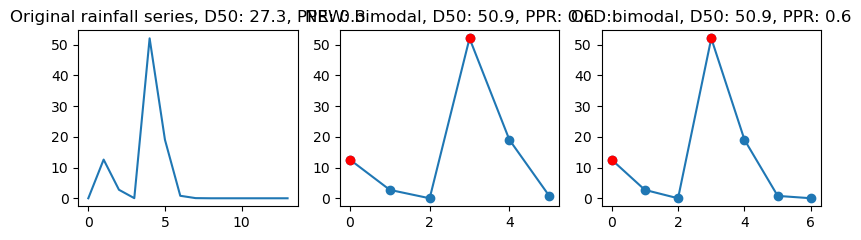

0.9918671646104931


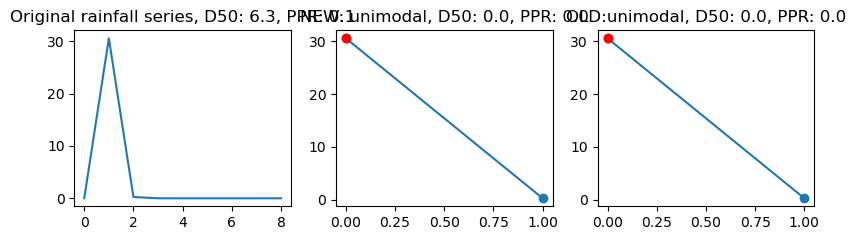

0.8771196707256661


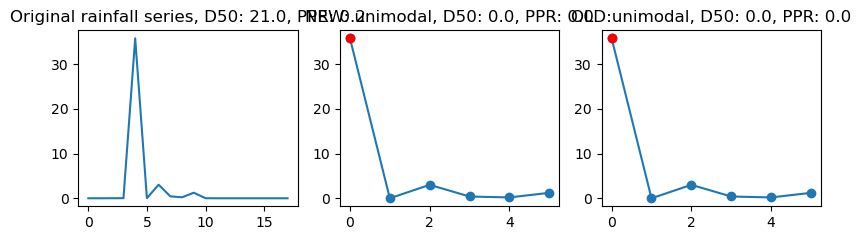

0.7360538729105125


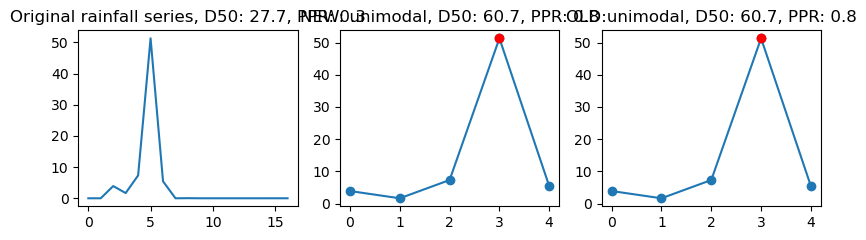

0.5505992694586856


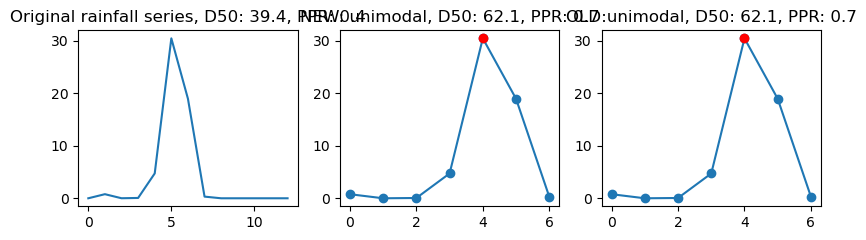

0.3903366134362381


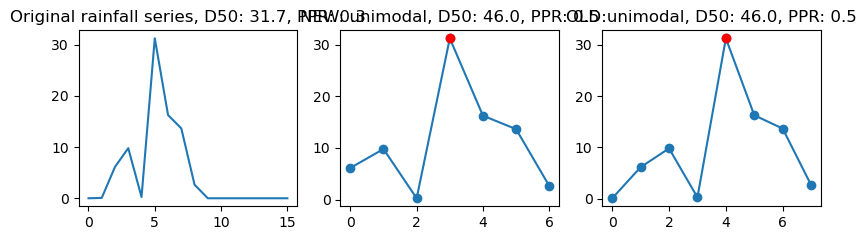

0.5251123192616769


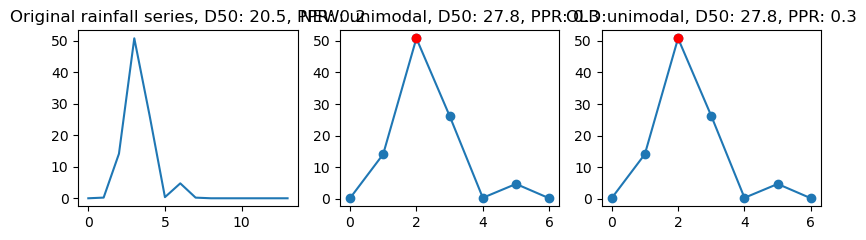

0.5988241399997811


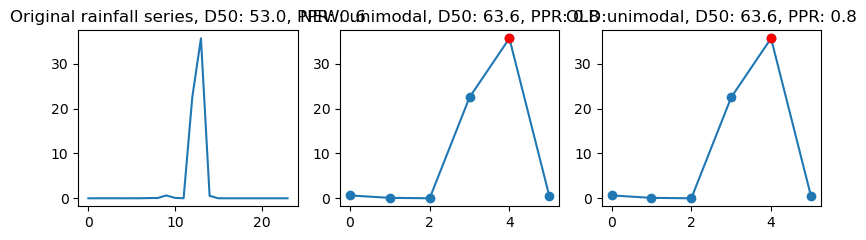

0.46003959608889794


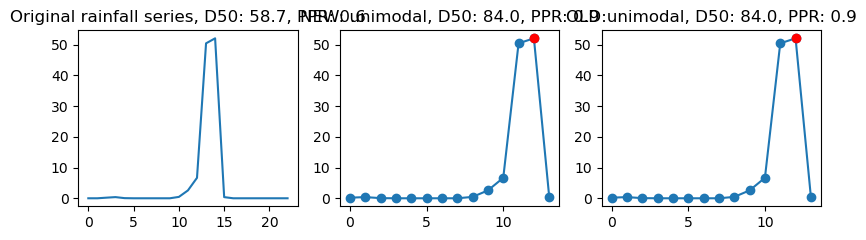

0.6024024869775314


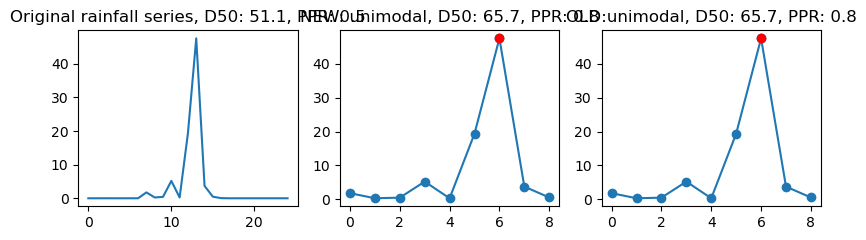

0.27055668430340335


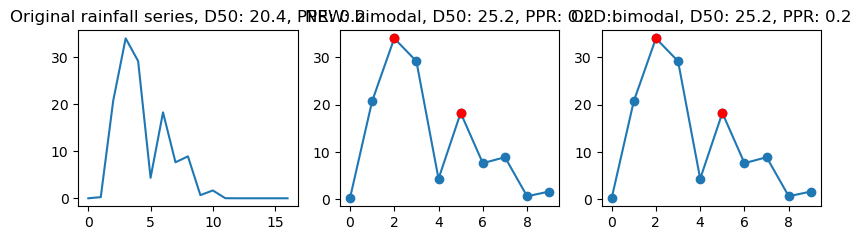

0.6977570843660456


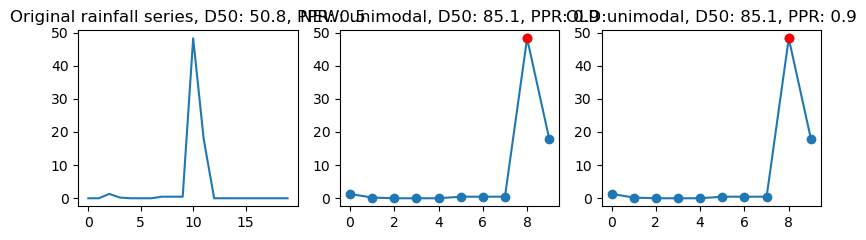

0.4668848817254086


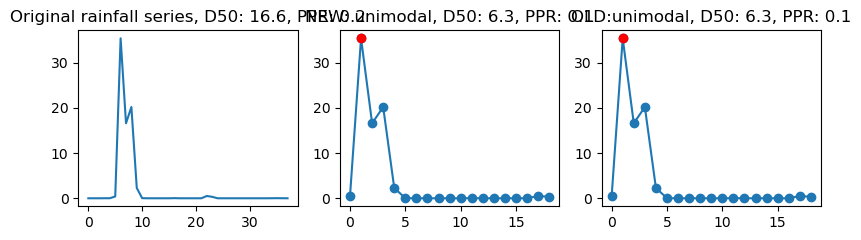

0.7160355774123545


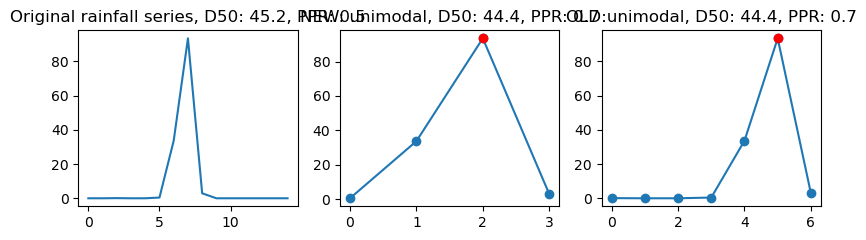

0.6946133578256222


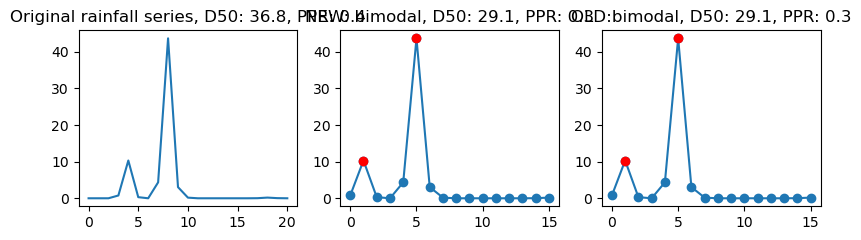

0.9980849168992206


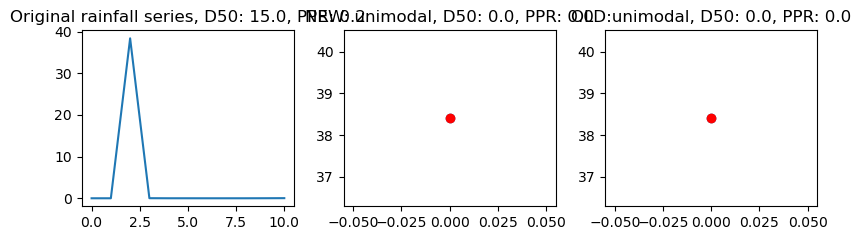

0.4045326970132085


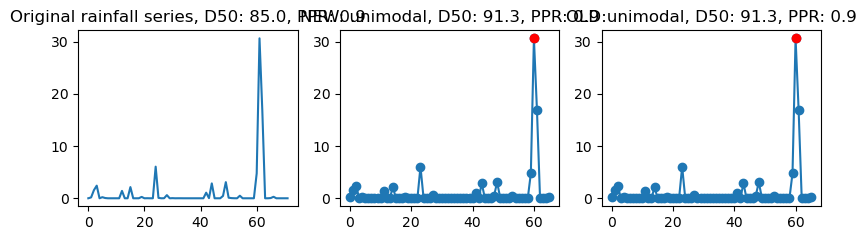

0.7365347783368356


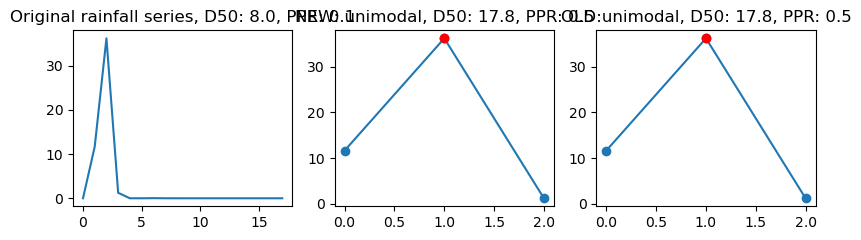

0.4609793502352124


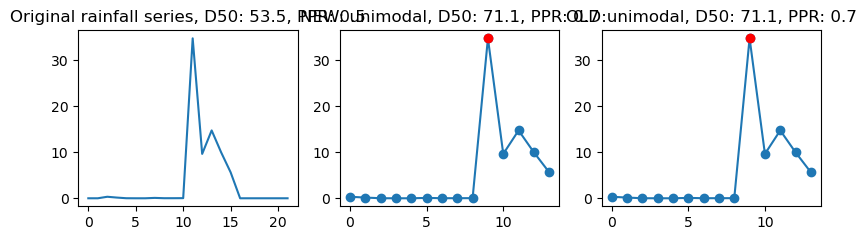

0.30408834979229044


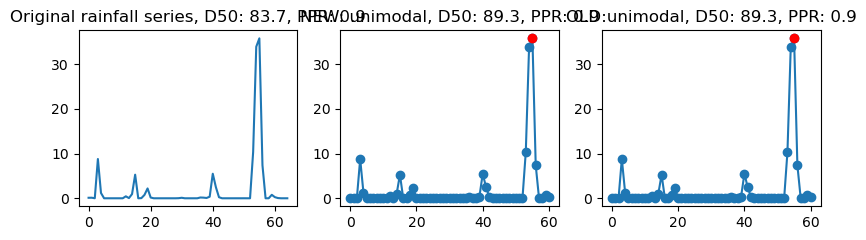

0.4996214114799378


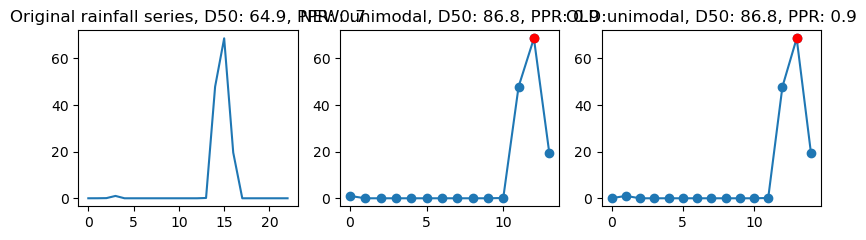

0.6256417545020798


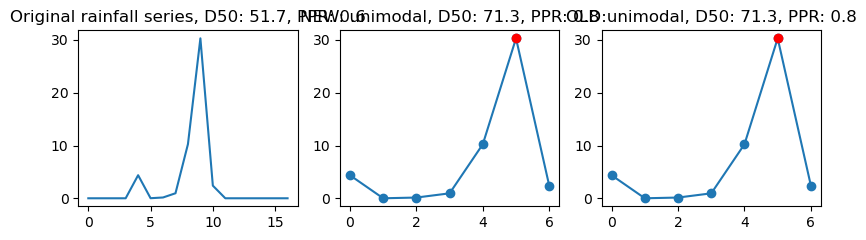

0.288164145906293


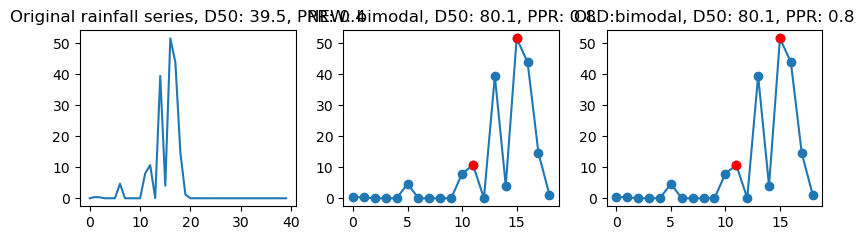

0.7827602823530365


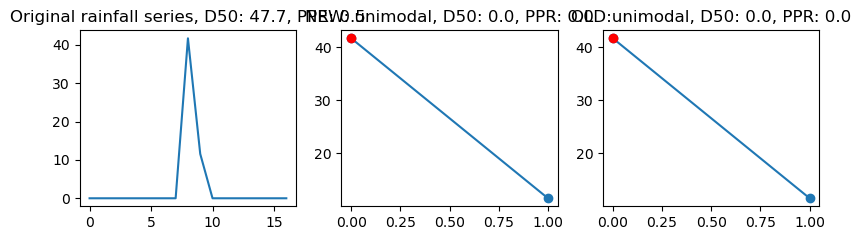

0.6327301100670902


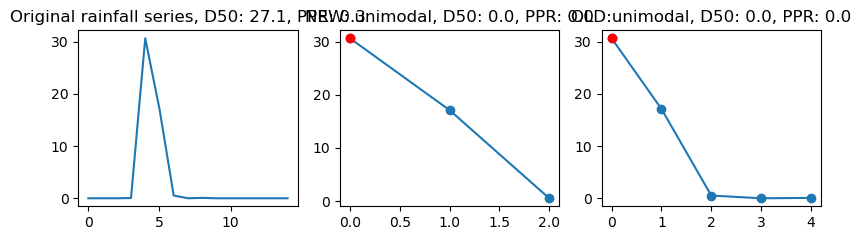

0.903816598042824


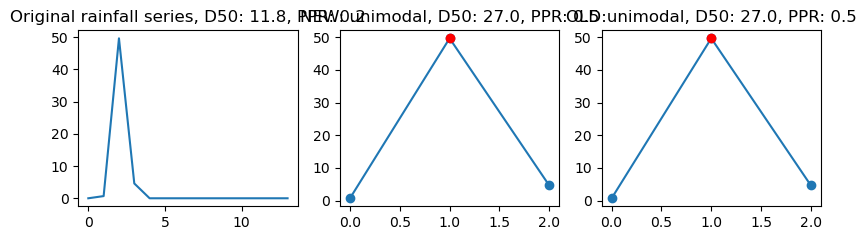

0.4745778272947545


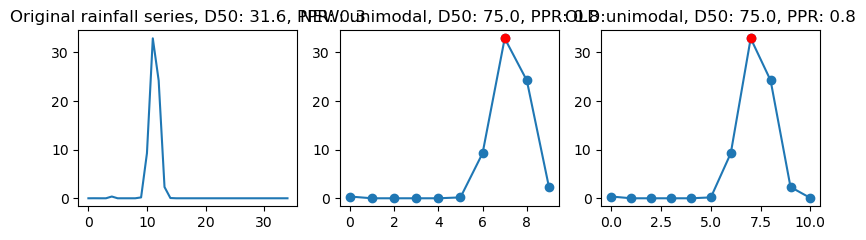

0.7986421013761132


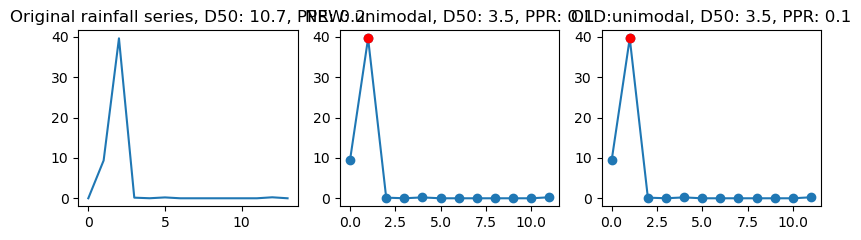

0.8756943314108998


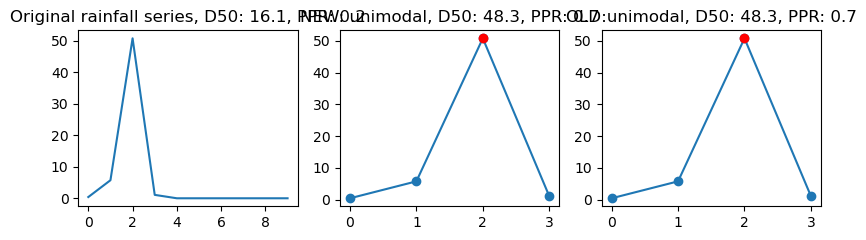

0.6912031683244533


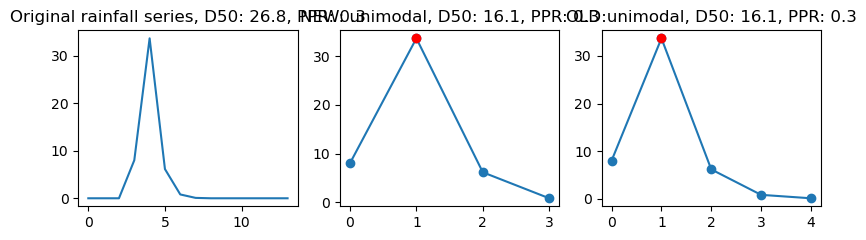

0.7209753004565029


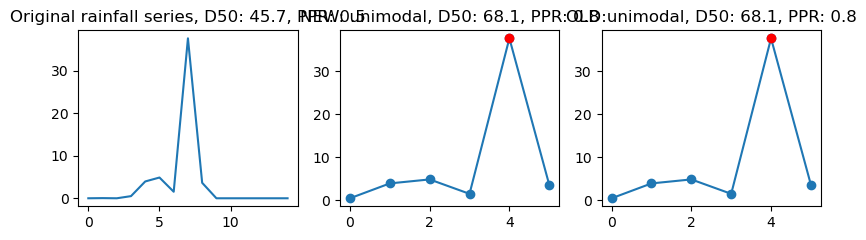

0.9136745874885082


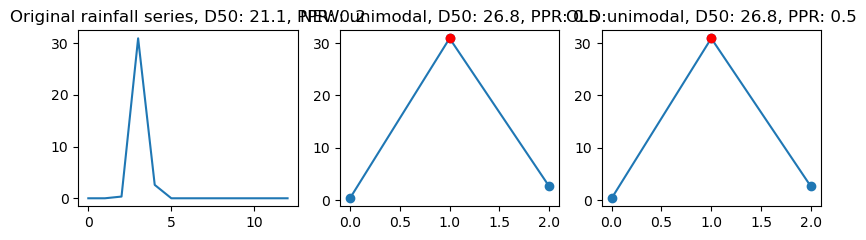

0.5330505805832995


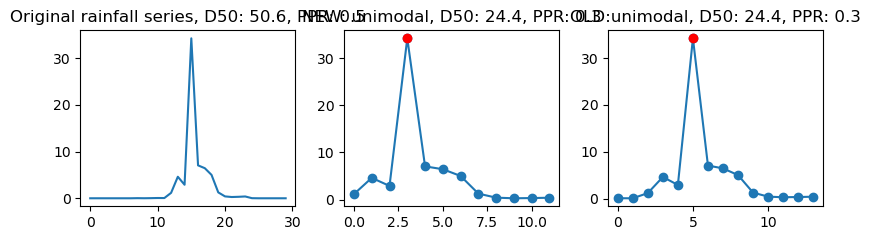

0.33713663657948306


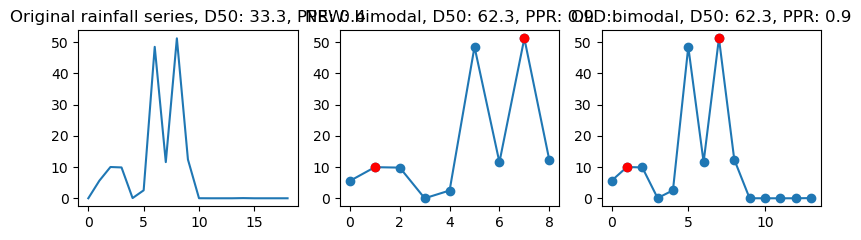

0.37362975137905


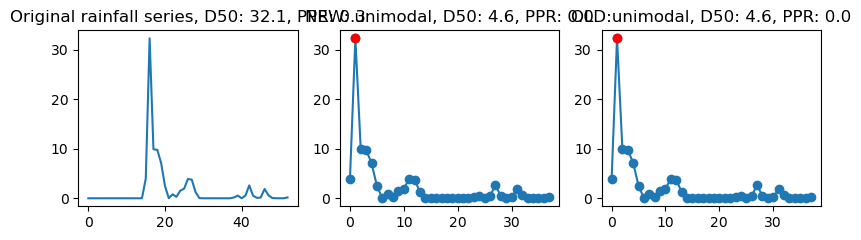

0.3805173168501332


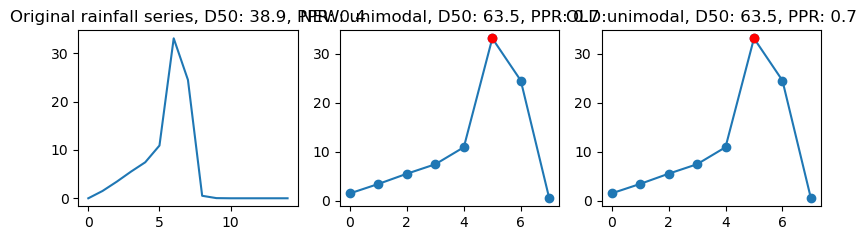

0.5436101852512393


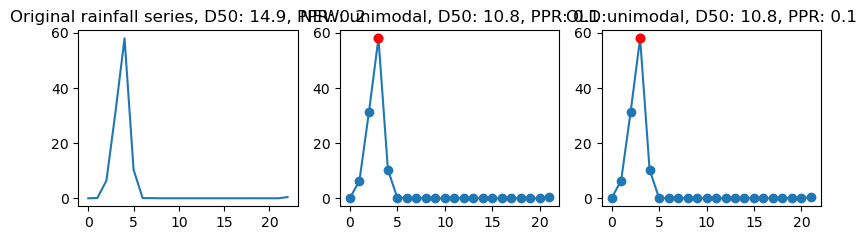

0.9902094455485925


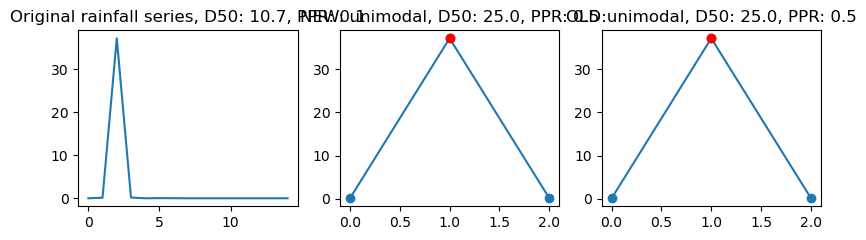

0.6276388235345175


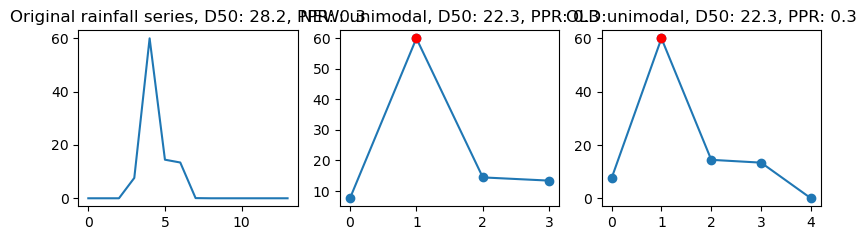

0.35011984806129387


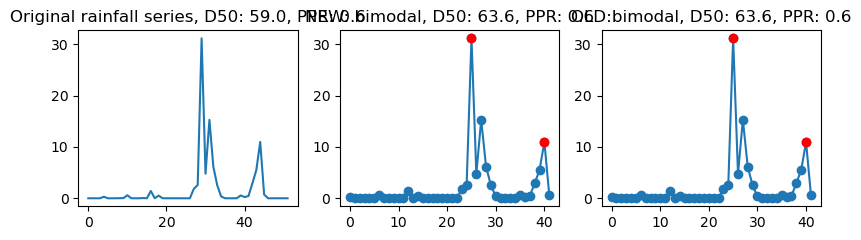

0.6089836810706527


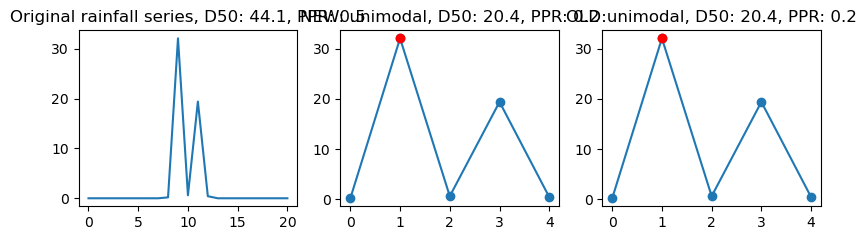

0.4680979060560622


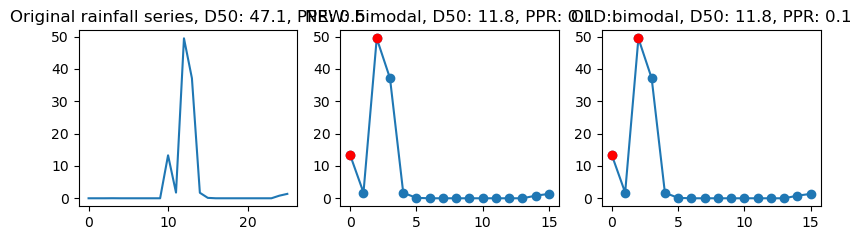

0.5340456955320144


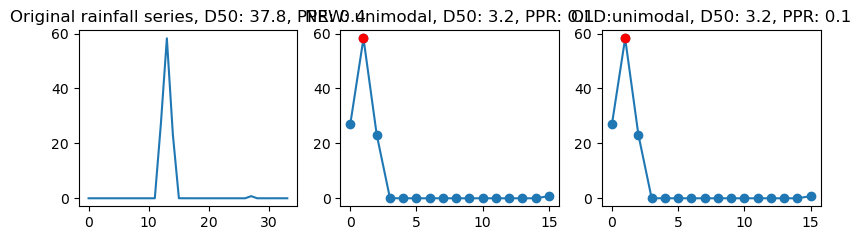

0.917276823276436


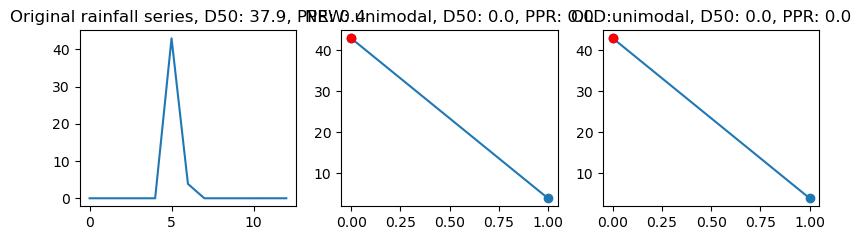

0.5796898108700272


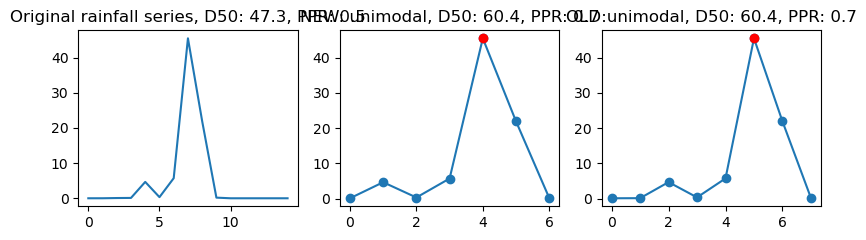

0.47935593997298137


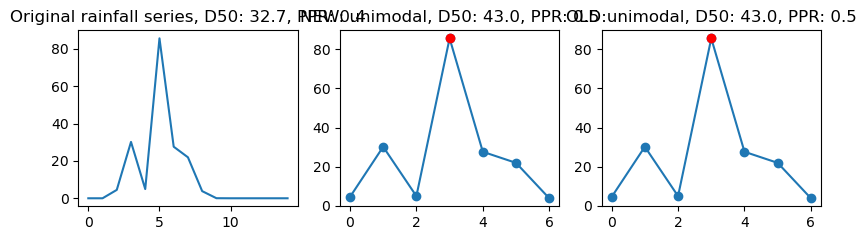

0.2995192695077249


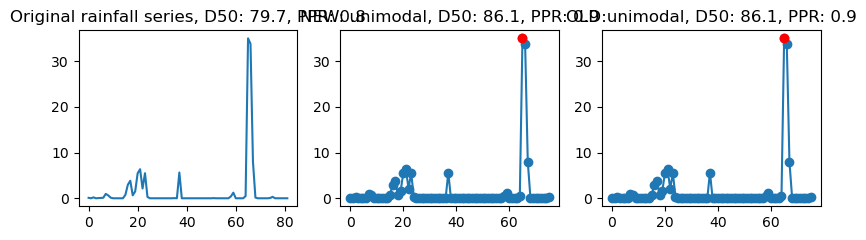

0.6625876618583718


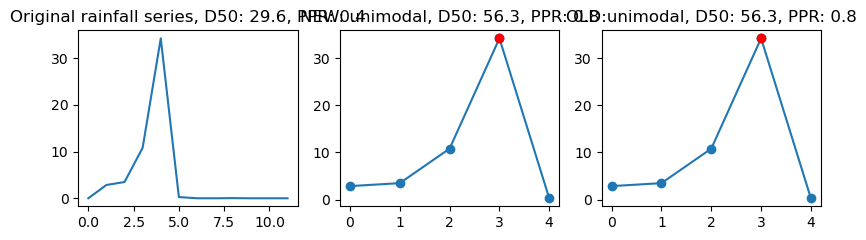

0.5794390095063549


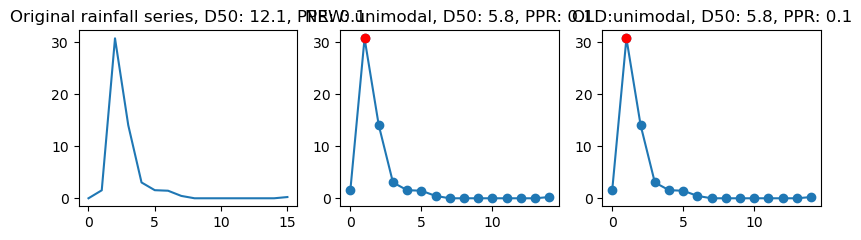

0.5856765392858448


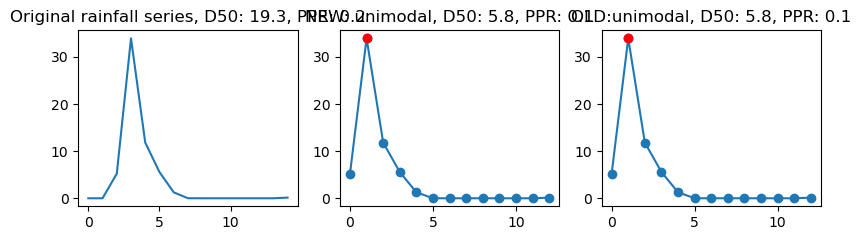

0.7632336848493403


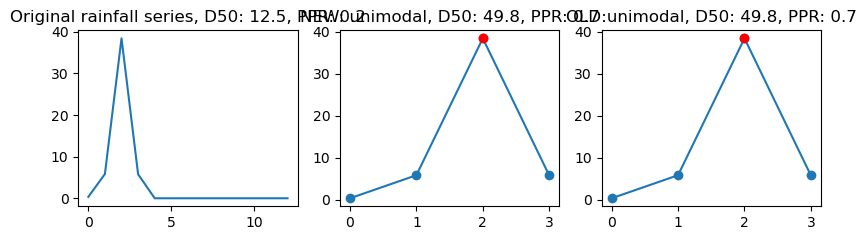

0.5898407235712181


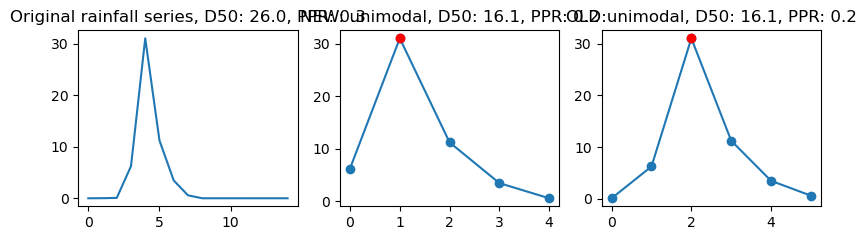

0.9381733339923666


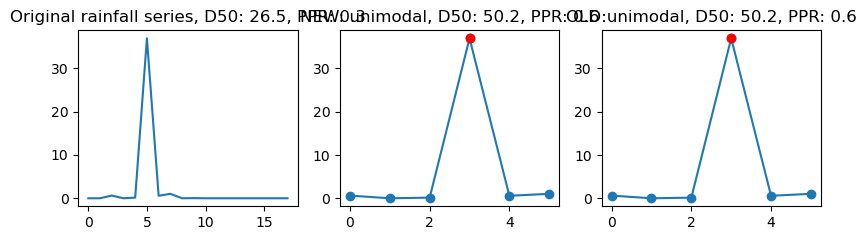

0.6005542045701762


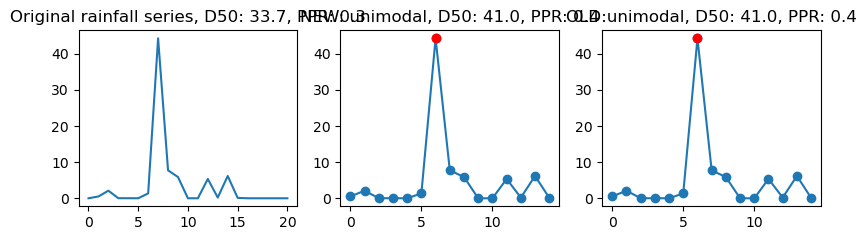

0.734382866057197


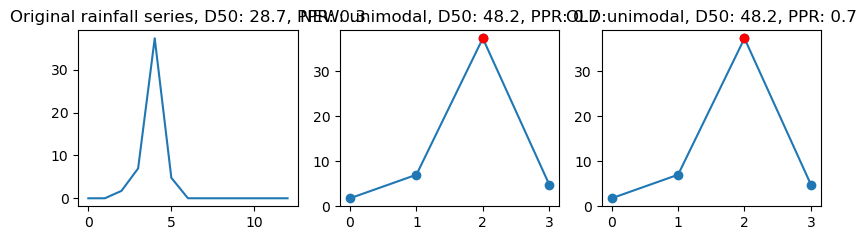

0.3458734474719323


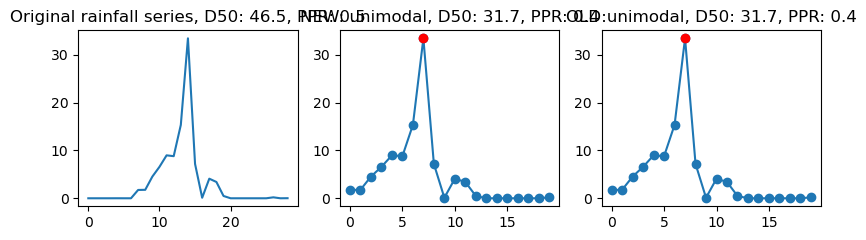

0.46630354687062575


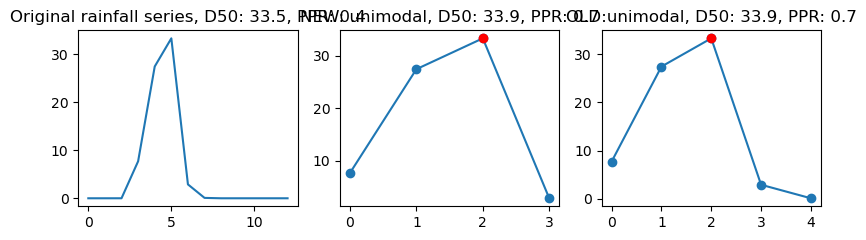

0.9411470622098078


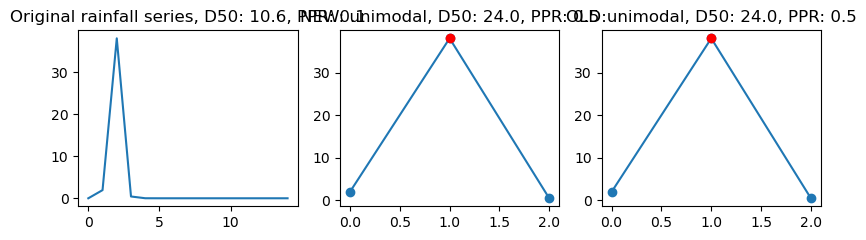

0.6840910342032654


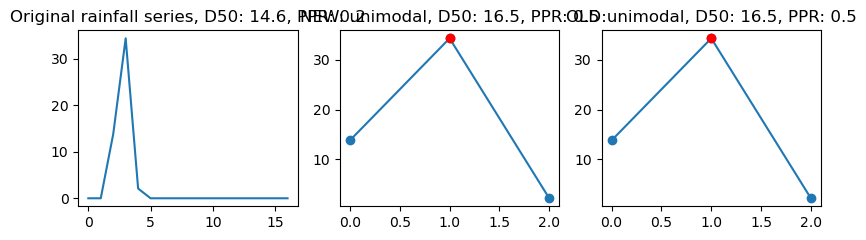

0.8410492096174802


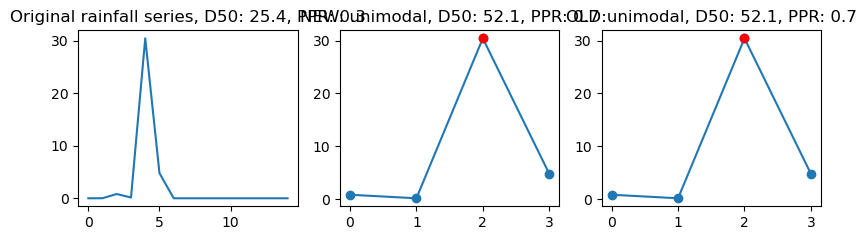

0.5041564502350264


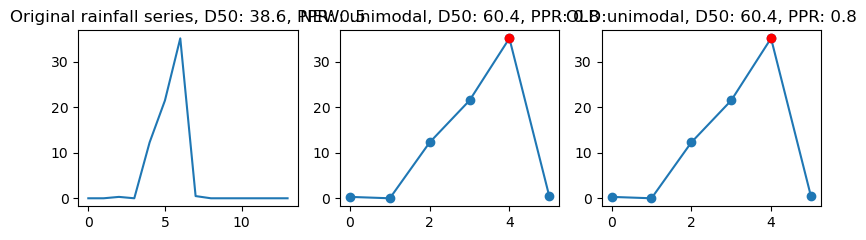

0.5952837079963678


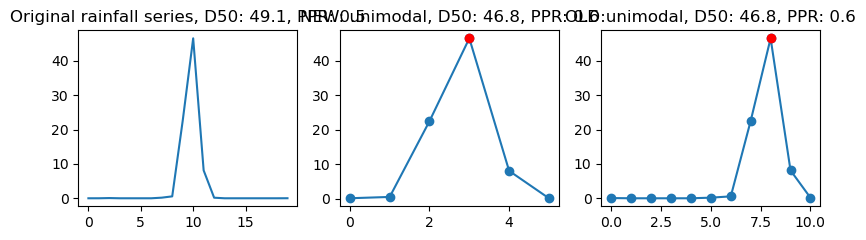

0.3939143028632939


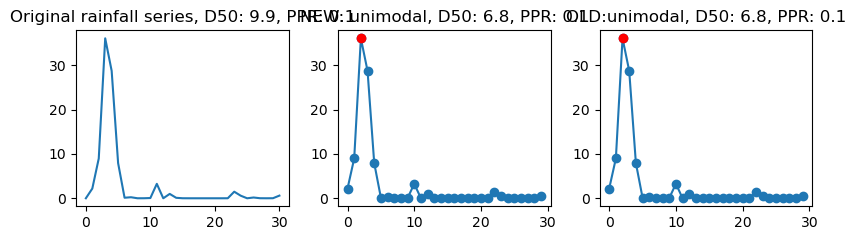

0.7061247090742553


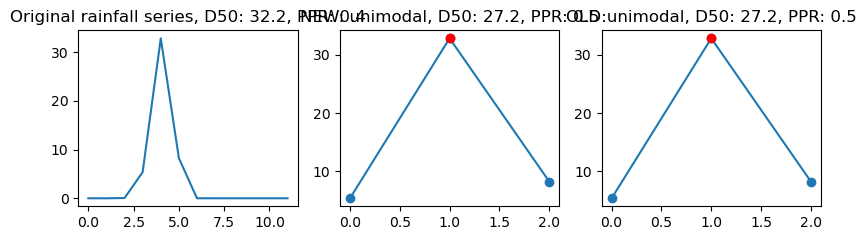

0.4589910834486824


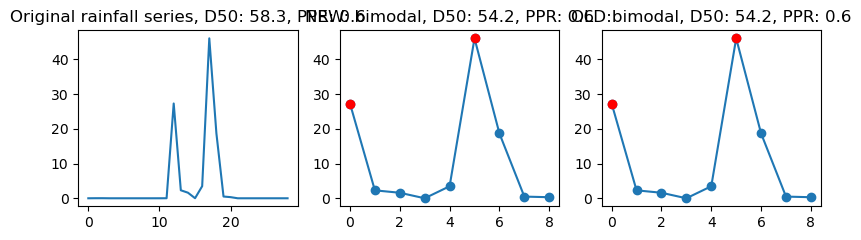

0.5479789177871548


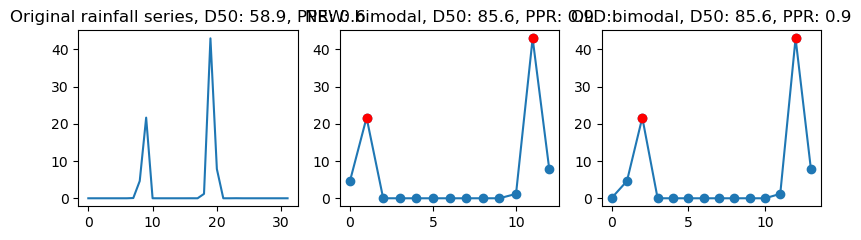

0.41145786248289645


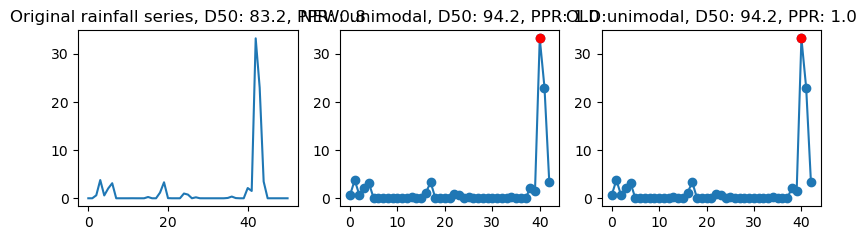

0.646089013814746


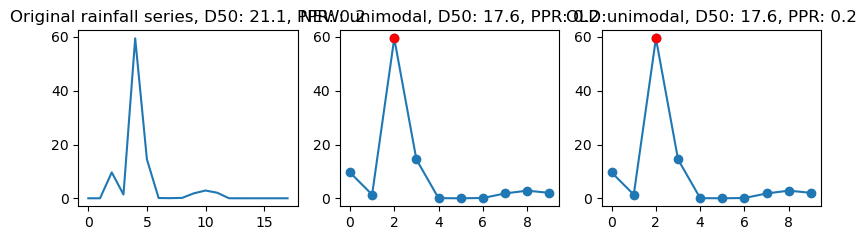

0.5365379870372518


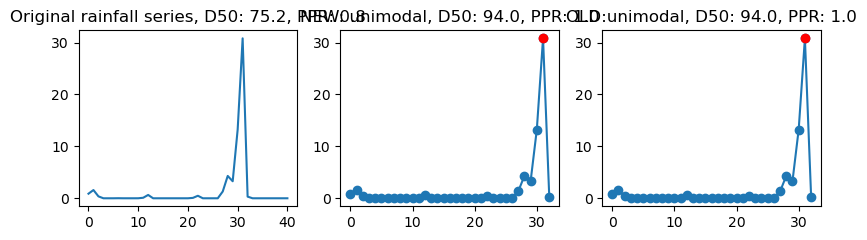

0.719285931982442


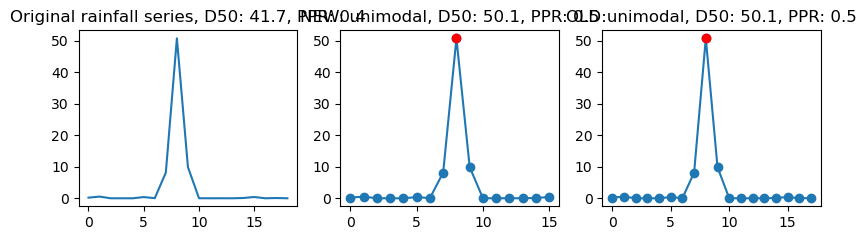

0.7241945287461288


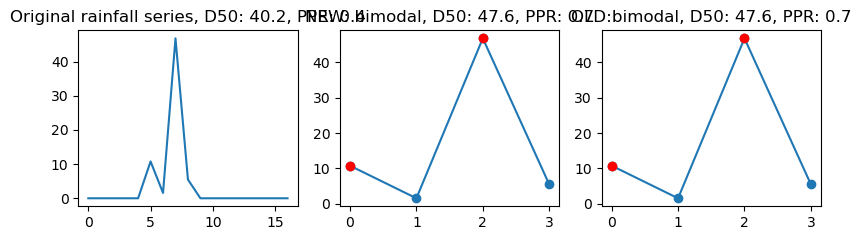

0.5778065028104311


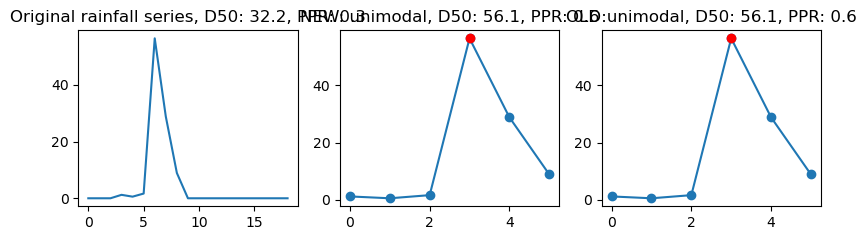

0.47665198275199905


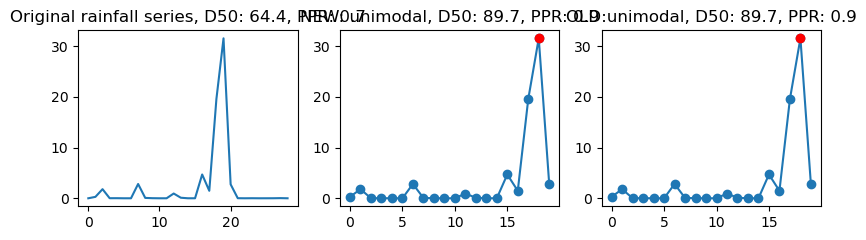

0.5927543457839578


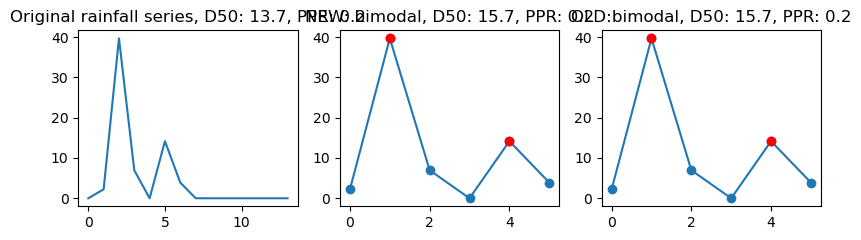

0.29496131008832993


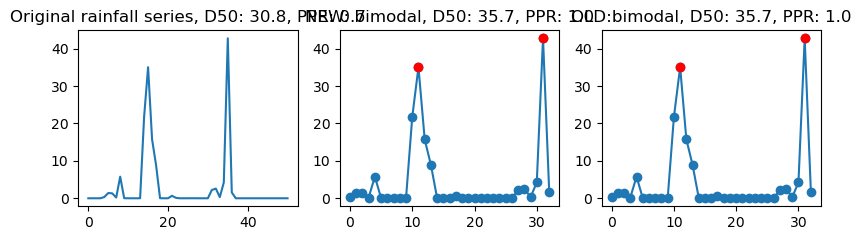

0.6604672726807312


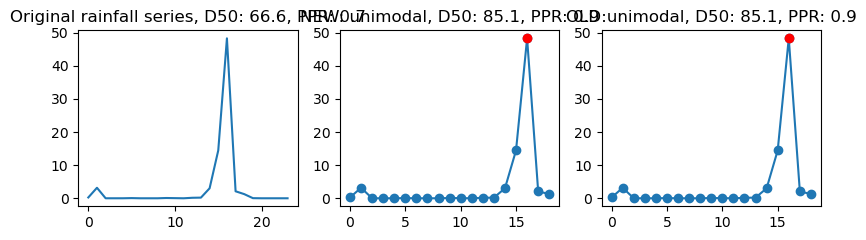

0.6478929067000867


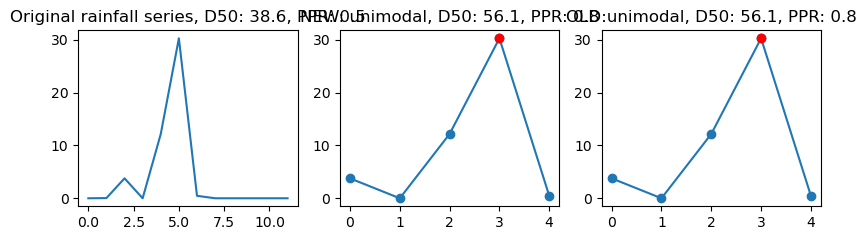

0.5515003721529664


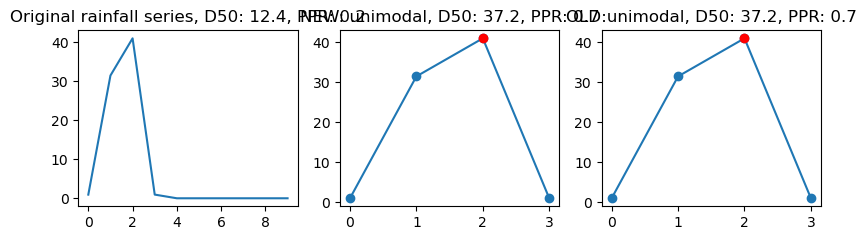

0.3923194439519956


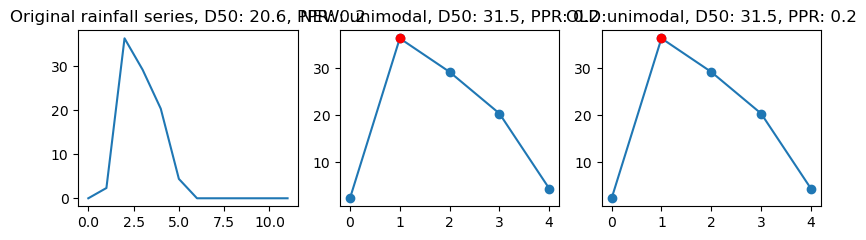

0.483302722300476


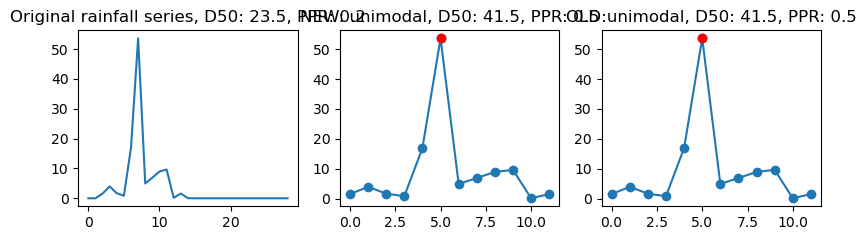

0.5883850816322252


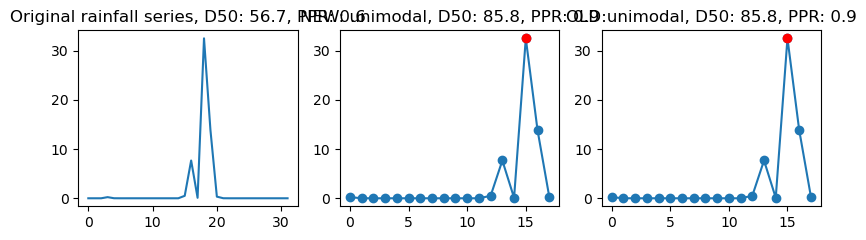

0.6102921923010732


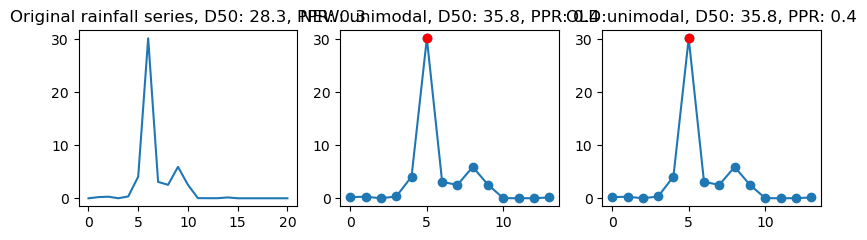

0.5023177533801966


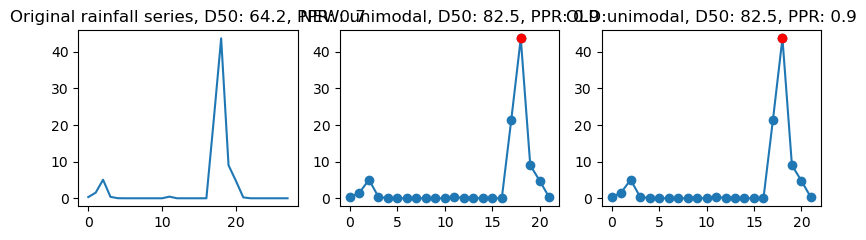

In [10]:
modal_class = []
for idx, row in sub.iterrows():
    print(row['peak_share'])
    values = np.fromstring(row["values"].strip("[]"), sep=" ")

    # Remove leading/trailing values below wet threshold
    wet = values > 0.1
    nonzero = np.flatnonzero(wet)

    if len(nonzero) == 0:
        continue

    trimmed_values = values[nonzero[0]:nonzero[-1] + 1]
    
    # Remove leading/trailing values below wet threshold
    wet = values > 0.05
    nonzero = np.flatnonzero(wet)

    if len(nonzero) == 0:
        continue

    trimmed_values_old = values[nonzero[0]:nonzero[-1] + 1]
    
    # print(trimmed_values)
    result = classify_modality(trimmed_values)
    result_old = classify_modality(trimmed_values_old)
    modal_class.append(result['modality'])
    #print(f"Event index: {idx}, result: {result['modality']}, n_peaks: {result['n_peaks']}")

    fig, axs = plt.subplots(ncols=3, figsize=(8, 2.5))
    axs[0].plot(values)
    axs[0].set_title(f"Original rainfall series, D50: {row['d50']:.1f}, PPR: {row['peak_position_ratio']:.1f}")
    axs[1].plot(trimmed_values, marker="o")
    axs[1].scatter(result["peaks"], trimmed_values[result["peaks"]], color="red", zorder=3)
    axs[1].set_title(f"NEW: {result['modality']}, D50: {row['d50_n']:.1f}, PPR: {row['peak_position_ratio_n']:.1f}")
    
    axs[2].plot(trimmed_values_old, marker="o")
    axs[2].scatter(result_old["peaks"], trimmed_values_old[result_old["peaks"]], color="red", zorder=3)
    axs[2].set_title(f"OLD:{result_old['modality']}, D50: {row['d50_n']:.1f}, PPR: {row['peak_position_ratio_n']:.1f}")    
    
    plt.tight_layout()
    plt.show()

sub['modal_class'] = modal_class

### Build multiple linear regression

In [47]:
features = ["max_precip", "total_acc", "d50_n"]
X = unimodal_events[features]
y = unimodal_events["10cm_area"]

# --- fit ---
model = LinearRegression().fit(X, y)
print("Intercept:", round(model.intercept_, 3))
print("Coefficients (change in 10cm_area per 1 unit of each variable):")
print(pd.Series(model.coef_, index=features).round(4))

# --- how accurate is the model? ---
print("\nR2, in-sample:", round(model.score(X, y), 3))

cv_pred = cross_val_predict(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=0))
print("R2, cross-validated:", round(r2_score(y, cv_pred), 3))      # the honest number: tested on events not used for fitting
print("RMSE (cv):", round(np.sqrt(mean_squared_error(y, cv_pred)), 3), "| MAE (cv):", round(mean_absolute_error(y, cv_pred), 3))

# --- how much does each variable contribute? ---
full_r2 = model.score(X, y)
rows = []
for f in features:
    others = [c for c in features if c != f]
    r2_alone = LinearRegression().fit(X[[f]], y).score(X[[f]], y)                   # R2 using only this variable
    r2_without = LinearRegression().fit(X[others], y).score(X[others], y)           # R2 using everything except it
    rows.append({"variable": f, "R2_alone": r2_alone, "R2_lost_if_removed": full_r2 - r2_without})
print("\n", pd.DataFrame(rows).round(3).to_string(index=False))

# --- coefficients on a common scale (so the two variables can be compared) ---
Xz, yz = (X - X.mean()) / X.std(), (y - y.mean()) / y.std()
print("\nStandardised coefficients (SD change in 10cm_area per 1 SD change in the variable):")
print(pd.Series(LinearRegression().fit(Xz, yz).coef_, index=features).round(3))

def cv_r2(cols):
    p = cross_val_predict(LinearRegression(), unimodal_events[cols], y, cv=KFold(5, shuffle=True, random_state=1))
    return r2_score(y, p)
print(cv_r2(["max_precip", "total_acc"]), cv_r2(features))

# --- prediction (pass a DataFrame so the column names match) ---
# print("\nPrediction for max_precip=30, total_acc=300:", model.predict(pd.DataFrame([[30, 300]], columns=features)))

Intercept: -0.313
Coefficients (change in 10cm_area per 1 unit of each variable):
max_precip    0.0124
total_acc     0.0028
d50_n         0.0015
dtype: float64

R2, in-sample: 0.871
R2, cross-validated: 0.842
RMSE (cv): 0.095 | MAE (cv): 0.076

   variable  R2_alone  R2_lost_if_removed
max_precip     0.760               0.198
 total_acc     0.665               0.046
     d50_n     0.102               0.029

Standardised coefficients (SD change in 10cm_area per 1 SD change in the variable):
max_precip    0.635
total_acc     0.319
d50_n         0.180
dtype: float64
0.8196439114464893 0.8452804674260468


In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

features = ["max_precip", "total_acc", "d50_n"]
X = unimodal[features]
y = unimodal["10cm_area"]

# --- fit ---
model = LinearRegression().fit(X, y)
print("Intercept:", round(model.intercept_, 3))
print("Coefficients (change in 10cm_area per 1 unit of each variable):")
print(pd.Series(model.coef_, index=features).round(4))

# --- how accurate is the model? ---
print("\nR2, in-sample:", round(model.score(X, y), 3))

cv_pred = cross_val_predict(LinearRegression(), X, y, cv=KFold(5, shuffle=True, random_state=0))
print("R2, cross-validated:", round(r2_score(y, cv_pred), 3))      # the honest number: tested on events not used for fitting
print("RMSE (cv):", round(np.sqrt(mean_squared_error(y, cv_pred)), 3), "| MAE (cv):", round(mean_absolute_error(y, cv_pred), 3))

# --- how much does each variable contribute? ---
full_r2 = model.score(X, y)
rows = []
for f in features:
    others = [c for c in features if c != f]
    r2_alone = LinearRegression().fit(X[[f]], y).score(X[[f]], y)                   # R2 using only this variable
    r2_without = LinearRegression().fit(X[others], y).score(X[others], y)           # R2 using everything except it
    rows.append({"variable": f, "R2_alone": r2_alone, "R2_lost_if_removed": full_r2 - r2_without})
print("\n", pd.DataFrame(rows).round(3).to_string(index=False))

# --- coefficients on a common scale (so the two variables can be compared) ---
Xz, yz = (X - X.mean()) / X.std(), (y - y.mean()) / y.std()
print("\nStandardised coefficients (SD change in 10cm_area per 1 SD change in the variable):")
print(pd.Series(LinearRegression().fit(Xz, yz).coef_, index=features).round(3))

def cv_r2(cols):
   p = cross_val_predict(LinearRegression(), sub[cols], y, cv=KFold(5, shuffle=True, random_state=1))
   return r2_score(y, p)
print(cv_r2(["max_precip", "total_acc"]), cv_r2(features))

# --- prediction (pass a DataFrame so the column names match) ---
# print("\nPrediction for max_precip=30, total_acc=300:", model.predict(pd.DataFrame([[30, 300]], columns=features)))

Intercept: -0.325
Coefficients (change in 10cm_area per 1 unit of each variable):
max_precip    0.0136
total_acc     0.0022
d50_n         0.0015
dtype: float64

R2, in-sample: 0.86
R2, cross-validated: 0.812
RMSE (cv): 0.103 | MAE (cv): 0.08

   variable  R2_alone  R2_lost_if_removed
max_precip     0.751               0.274
 total_acc     0.571               0.050
     d50_n     0.093               0.031

Standardised coefficients (SD change in 10cm_area per 1 SD change in the variable):
max_precip    0.670
total_acc     0.296
d50_n         0.183
dtype: float64
0.8112494951461715 0.8348796602855441


In [45]:
unimodal_events = sub[sub['modal_class'] =='unimodal']

In [65]:
# xvar, yvar = "max_precip", "10cm_area"

# # Apply the same NaN filter the regression uses, *before* counting,
# # so ">20 events" means >20 usable events
# clean = rainfall_events_all_df.dropna(subset=[xvar, yvar, "hc_at_peak"])
# clean = clean[clean["peak_cell_id"] >= 0]      # ngroup gives -1 for NaN indices

# counts = clean["peak_cell_id"].value_counts()
# busy_ids = counts[counts > 20].index
# print(f"{len(busy_ids)} pixels with >20 events")

# # R² and p for each busy pixel
# rows = []
# for pid, sub in clean[clean["peak_cell_id"].isin(busy_ids)].groupby("peak_cell_id"):
#     r2, p = find_linear_relationship(sub, yvar, xvar)
#     spearmans_corr, spearmans_p_value = stats.spearmanr(sub[yvar], sub[xvar])
#     rows.append({"peak_cell_id": pid, "r2": r2, "p": p, "n": len(sub),
#                  "x_idx_global": sub["x_idx_global"].iloc[0],
#                  "y_idx_global": sub["y_idx_global"].iloc[0],
#                  "spearmans_corr_coefficient":spearmans_corr,
#                 "x_coord": sub["x_coord"].iloc[0],
#                 "y_coord": sub["y_coord"].iloc[0],})

# pix_stats = pd.DataFrame(rows)
# pix_stats[["spearmans_corr_coefficient"]] = pix_stats[["spearmans_corr_coefficient"]].apply(pd.to_numeric, errors="coerce")
# pix_stats = pix_stats.dropna(subset=["spearmans_corr_coefficient"])

# top8 = pix_stats.nlargest(8, "spearmans_corr_coefficient")
# bottom8 = pix_stats.nsmallest(8, "spearmans_corr_coefficient")


# plot_pixel_grid(top8, "Pixels (>20 events) with highest R²"); plt.show()
# plot_pixel_grid(bottom8, "Pixels (>20 events) with lowest R²"); plt.show()